
# Prédiction de la durée d'un trajet en taxi à New York

**Module** : Fondements du Big Data, Projet 2 (Big Data distribué)
**Cible** : `trip_duration`, régression supervisée
**Notebook de référence** : [`headsortails/nyc-taxi-eda-update-the-fast-the-curious`](https://www.kaggle.com/code/headsortails/nyc-taxi-eda-update-the-fast-the-curious)
**Technologies** : Hadoop, HDFS, Apache Spark, PySpark, Spark SQL, Spark MLlib, FastAPI

| # | Étape | Contenu |
|---|-------|---------|
| [1](#etape-1) | BIG DATA | Contexte, les 3V, formats, justification de Spark |
| [2](#etape-2) | HADOOP / SPARK | HDFS réel, SparkSession, partitions, Spark SQL, Parquet |
| [3](#etape-3) | TRANSFORMATION | Nettoyage, GPS aberrants, distance, variables temporelles |
| [4](#etape-4) | MACHINE LEARNING | Spark MLlib, 4 modèles de régression |
| [5](#etape-5) | ÉVALUATION | RMSE, MAE, R², Spark contre Pandas |
| [6](#etape-6) | DÉPLOIEMENT | Modèle sauvegardé et API FastAPI |

**Le notebook de référence est écrit en R Markdown** et porte essentiellement sur
l'exploration. Nous n'exécutons pas de code R : nous reprenons ses analyses pertinentes en
PySpark, et nous ajoutons la partie modélisation qu'il ne couvre pas.

<a id="etape-1"></a>
# Étape 1 : BIG DATA

**Problématique** : estimer la durée d'un trajet à partir des seules informations connues
**au moment de la prise en charge**. Une application de réservation doit annoncer une durée
avant que le trajet ne commence.

**Contrainte méthodologique qui en découle** : toute variable produite *pendant* ou *après*
le trajet est interdite. Cela exclut la distance au compteur, le prix, le pourboire, le mode
de paiement, et bien sûr l'heure d'arrivée. Nous y revenons à l'étape 3.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

PROJET = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = PROJET / "data" / "raw"
DATA_PROC = PROJET / "data" / "processed"
MODELS = PROJET / "models"
REPORTS = PROJET / "reports"
FIGURES = REPORTS / "figures"
APP = PROJET / "app"
for d in (DATA_PROC, MODELS, REPORTS, FIGURES, APP):
    d.mkdir(parents=True, exist_ok=True)

GRAINE = 42
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
HADOOP = Path("/home/ssl/hadoop-3.4.0")
os.environ["PATH"] = f"{HADOOP / 'bin'}:{os.environ['PATH']}"

sys.path.insert(0, str(PROJET / "tools"))
import viz
viz.appliquer_style()

FICHIER = "yellow_tripdata_2016-01.parquet"
CHEMIN_LOCAL = DATA_RAW / FICHIER
CHEMIN_HDFS = f"hdfs://localhost:9000/nyc_taxi/raw/{FICHIER}"


def hdfs(commande):
    """Execute une commande HDFS et renvoie sa sortie texte."""
    r = subprocess.run(f"{HADOOP}/bin/{commande}", shell=True,
                       capture_output=True, text=True, env=os.environ)
    return (r.stdout + r.stderr).strip()


print(f"Projet : {PROJET}")
print(f"Java   : {os.environ['JAVA_HOME']}")

Projet : /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_2_NYC_TAXI_BIGDATA
Java   : /usr/lib/jvm/java-11-openjdk-amd64



## 1.1 Le dataset

**Source** : données ouvertes de la *NYC Taxi and Limousine Commission*, le régulateur des
taxis new-yorkais. Chaque course de taxi jaune y est enregistrée. Nous utilisons
**janvier 2016**, le même mois et la même source que le jeu Kaggle du notebook de référence,
qui en est un échantillon.

**Pourquoi la source officielle plutôt que l'extrait Kaggle** : 10,9 millions de courses
contre 1,46 million, soit 7 fois plus. Pour un projet dont le sujet est le traitement
distribué, travailler sur le jeu complet rend la démonstration plus honnête.

In [2]:
taille_octets = CHEMIN_LOCAL.stat().st_size
apercu = pd.read_parquet(CHEMIN_LOCAL, columns=["tpep_pickup_datetime"])
n_lignes = len(apercu)
del apercu

schema = pd.read_parquet(CHEMIN_LOCAL).head(3)
print(f"Fichier       : {FICHIER}")
print(f"Taille        : {taille_octets / 1024**2:.1f} Mo (Parquet compresse)")
print(f"Lignes        : {n_lignes:,}".replace(",", " "))
print(f"Colonnes      : {len(schema.columns)}")
print(f"Octets/ligne  : {taille_octets / n_lignes:.1f}")
display(schema)

Fichier       : yellow_tripdata_2016-01.parquet
Taille        : 144.2 Mo (Parquet compresse)
Lignes        : 10 905 067
Colonnes      : 19
Octets/ligne  : 13.9


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,1,2016-01-01 00:12:22,2016-01-01 00:29:14,1,3.2,1,N,48,262,1,14.0,0.5,0.5,3.06,0.0,0.3,18.36,None,None
1,1,2016-01-01 00:41:31,2016-01-01 00:55:10,2,1.0,1,N,162,48,2,9.5,0.5,0.5,0.00,0.0,0.3,10.80,None,None
2,1,2016-01-01 00:53:37,2016-01-01 00:59:57,1,0.9,1,N,246,90,2,6.0,0.5,0.5,0.00,0.0,0.3,7.30,None,None



## 1.2 Les trois V

| V | Ce que dit ce jeu | Verdict honnête |
|---|---|---|
| **Volume** | 145 Mo compressés, 10,9 M lignes pour un seul mois. Une année complète ferait environ 1,7 Go, et la série 2009-2024 dépasse 50 Go | **Modéré**. Un seul mois tient en mémoire sur une machine correcte |
| **Vélocité** | Environ 350 000 courses par jour, soit 4 par seconde en moyenne et davantage aux heures de pointe. Publication mensuelle en lot | **Faible en l'état**. Le flux temps réel existe chez l'opérateur, pas dans ce fichier |
| **Variété** | Une seule table, schéma stable, types homogènes | **Faible**. Données tabulaires très régulières |

### Ce jeu n'est pas du Big Data au sens industriel

Il faut le dire clairement plutôt que de gonfler l'argumentaire. 145 Mo tiennent dans la
mémoire d'un téléphone. Pandas charge ce fichier en quelques secondes. Aucune des trois
dimensions n'atteint le seuil qui rend un cluster *nécessaire*.

**Son intérêt est pédagogique, et il est réel.** Le jeu est assez gros pour que les
différences de comportement deviennent mesurables : partitionnement, évaluation paresseuse,
coût d'un `shuffle`, bénéfice du format colonne. Ce sont exactement les mécanismes qui
décident de la viabilité d'un traitement sur 50 Go. On les apprend ici à une échelle où
chaque exécution prend des secondes et non des heures.

### Ce qui justifie quand même Spark ici

1. **Le passage à l'échelle est gratuit.** Le code écrit pour ce mois traite les 15 années
   sans une ligne de changement, en ajoutant des machines.
2. **La tolérance aux pannes.** Spark recalcule une partition perdue à partir du lignage.
   Sur un traitement de plusieurs heures, c'est ce qui évite de tout reprendre.
3. **Le modèle de programmation.** Spark SQL décrit *ce que* l'on veut, pas *comment* le
   calculer. L'optimiseur Catalyst s'en charge, et son plan change selon le volume.


## 1.3 Pourquoi le format Parquet

Le jeu Kaggle est distribué en CSV, la TLC publie en Parquet. La différence n'est pas
cosmétique : elle conditionne la performance de tout le pipeline.

| | CSV | Parquet |
|---|---|---|
| Organisation | Par ligne | **Par colonne** |
| Compression | Aucune | Snappy, par colonne |
| Typage | Tout en texte, à convertir | Types conservés |
| Lecture partielle | Impossible, il faut tout lire | **Seules les colonnes utiles sont lues** |
| Statistiques | Aucune | Min, max et comptages par bloc |

Le dernier point est décisif. Un filtre `WHERE passenger_count > 6` laisse Spark écarter des
blocs entiers sans les décompresser, grâce aux statistiques stockées dans le fichier. On
appelle cela le *predicate pushdown*. Mesurons.

In [3]:
CHEMIN_CSV = DATA_RAW / "echantillon.csv"

# Echantillon : convertir 10,9 M de lignes en CSV produirait environ 1,8 Go
echantillon = pd.read_parquet(CHEMIN_LOCAL).head(500_000)
if not CHEMIN_CSV.exists():
    echantillon.to_csv(CHEMIN_CSV, index=False)
echantillon.to_parquet(DATA_RAW / "echantillon.parquet", index=False)

taille_csv = CHEMIN_CSV.stat().st_size
taille_pq = (DATA_RAW / "echantillon.parquet").stat().st_size

def chronometre(fonction, repetitions=3):
    durees = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction()
        durees.append(time.perf_counter() - debut)
    return min(durees)

t_csv = chronometre(lambda: pd.read_csv(CHEMIN_CSV))
t_pq = chronometre(lambda: pd.read_parquet(DATA_RAW / "echantillon.parquet"))
t_pq_1col = chronometre(
    lambda: pd.read_parquet(DATA_RAW / "echantillon.parquet", columns=["trip_distance"]))

display(pd.DataFrame({
    "taille_Mo": [taille_csv / 1024**2, taille_pq / 1024**2, taille_pq / 1024**2],
    "lecture_s": [t_csv, t_pq, t_pq_1col],
}, index=["CSV complet", "Parquet complet", "Parquet, 1 colonne"]).round(3))

print(f"Compression : x{taille_csv / taille_pq:.1f}")
print(f"Lecture complete : x{t_csv / t_pq:.1f} plus rapide")
print(f"Lecture d'une seule colonne : x{t_csv / t_pq_1col:.1f} plus rapide que le CSV")

,taille_Mo,lecture_s
CSV complet,44.751,0.555
Parquet complet,7.674,0.032
"Parquet, 1 colonne",7.674,0.005


Compression : x5.8
Lecture complete : x17.1 plus rapide
Lecture d'une seule colonne : x116.0 plus rapide que le CSV



## 1.4 Problématiques de stockage et de traitement

**Stockage.** Un fichier de 145 Mo tient sur n'importe quel disque. Quinze années de
données, soit plus de 50 Go, posent trois problèmes qu'un système de fichiers classique ne
résout pas : la panne disque fait tout perdre, la lecture est limitée par un seul bras de
lecture, et aucune machine du commerce ne garde cela en mémoire. **HDFS** répond aux trois
en découpant les fichiers en blocs répliqués sur plusieurs machines.

**Traitement.** Un agrégat sur 50 Go en Pandas exige 50 Go de mémoire vive, plus les copies
intermédiaires. **Spark** traite les données par partitions, en mémoire quand elle suffit,
sur disque quand elle manque, et répartit le calcul sur plusieurs cœurs ou machines.

**Ce que nous faisons réellement dans ce notebook.** Un cluster mono-nœud : HDFS tourne avec
un NameNode et un DataNode sur cette seule machine, Spark en mode `local[*]` utilise les
cœurs du processeur. **Ce n'est pas du calcul distribué sur plusieurs machines**, et nous ne
prétendrons pas le contraire. C'est en revanche la même API, le même code, les mêmes
mécanismes de partitionnement : le passage à un vrai cluster ne demanderait que de changer
l'URL du maître.


<a id="etape-2"></a>
# Étape 2 : HADOOP et SPARK

## 2.1 Architecture HDFS

HDFS découpe chaque fichier en **blocs de 128 Mo par défaut**, répartis sur les machines du
cluster et répliqués.

| Composant | Rôle |
|---|---|
| **NameNode** | Garde en mémoire l'arborescence et la carte fichier vers blocs. Il ne stocke aucune donnée. C'est le point unique de défaillance. |
| **DataNode** | Stocke les blocs et répond directement aux clients. Envoie un battement de cœur au NameNode toutes les 3 secondes. |
| **SecondaryNameNode** | Fusionne périodiquement le journal des modifications avec l'image du système de fichiers. Ce n'est **pas** un NameNode de secours, malgré son nom. |

Trois principes expliquent les choix de conception :

1. **Écrire une fois, lire souvent.** Pas de modification en place, seulement de l'ajout.
   Cela simplifie énormément la cohérence.
2. **Déplacer le calcul vers les données.** Transférer 128 Mo coûte plus cher qu'envoyer le
   programme sur la machine qui les détient.
3. **La panne est la norme.** Avec mille machines, il y en a toujours une en panne. D'où la
   réplication, par défaut sur 3 machines.

**Sur notre installation** : un seul nœud, donc `dfs.replication = 1`. Une panne disque
perdrait tout. C'est acceptable pour un travail pédagogique, inacceptable en production.

In [4]:
print(hdfs("hdfs dfsadmin -report").split("Live datanodes")[0][:700])

Configured Capacity: 250161205248 (232.98 GB)
Present Capacity: 9760755712 (9.09 GB)
DFS Remaining: 9432838144 (8.79 GB)
DFS Used: 327917568 (312.73 MB)
DFS Used%: 3.36%
Replicated Blocks:
	Under replicated blocks: 4
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 4
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-------------------------------------------------



In [5]:
print("Contenu du repertoire HDFS :")
print(hdfs("hdfs dfs -ls -h /nyc_taxi/raw"))
print("\nDecoupage en blocs du fichier principal :")
rapport = hdfs(f"hdfs fsck /nyc_taxi/raw/{FICHIER} -files -blocks")
for ligne in rapport.splitlines():
    if any(m in ligne for m in ["Total size", "Total blocks", "len=", "Status", "replication"]):
        print("  " + ligne.strip()[:110])

Contenu du repertoire HDFS :


Found 2 items
-rw-r--r--   1 ssl supergroup     12.0 K 2026-11-12 21:11 /nyc_taxi/raw/taxi_zone_lookup.csv
-rw-r--r--   1 ssl supergroup    144.2 M 2026-11-12 21:08 /nyc_taxi/raw/yellow_tripdata_2016-01.parquet

Decoupage en blocs du fichier principal :


  /nyc_taxi/raw/yellow_tripdata_2016-01.parquet 151251087 bytes, replicated: replication=1, 2 block(s):  OK
  0. BP-1850973315-127.0.1.1-1791904907873:blk_1073742054_1230 len=134217728 Live_repl=1
  1. BP-1850973315-127.0.1.1-1791904907873:blk_1073742055_1231 len=17033359 Live_repl=1
  Status: HEALTHY
  Total size:	151251087 B
  Total blocks (validated):	2 (avg. block size 75625543 B)
  Default replication factor:	1
  Average block replication:	1.0
  Blocks queued for replication:	0
  Total size:	0 B
  Blocks queued for replication:	0



**Lecture du résultat** : 151 Mo découpés en **2 blocs**, le premier plein à 128 Mo, le
second contenant le reste. Sur un vrai cluster, ces deux blocs vivraient sur deux machines
différentes et seraient lus en parallèle. Ici ils sont sur le même disque : le
parallélisme est celui des cœurs du processeur, pas celui des machines.

## 2.2 MapReduce contre Spark

| | Hadoop MapReduce | Apache Spark |
|---|---|---|
| Unité de calcul | Map puis Reduce, imposés | Graphe de transformations quelconque |
| Entre deux étapes | Écriture sur disque | **En mémoire** |
| Itérations | Relit le disque à chaque tour | Garde le jeu en mémoire |
| Code | Verbeux, Java | DataFrames, SQL, Python |
| Ordre de grandeur | Référence | 10 à 100 fois plus rapide sur l'itératif |

Le gain vient d'un seul point : MapReduce **matérialise sur disque** le résultat de chaque
étape. Un algorithme d'apprentissage qui fait 100 passes sur les données écrit et relit 100
fois. Spark garde la partition en mémoire et ne l'écrit que si nécessaire.

C'est décisif pour l'étape 4 : entraîner un modèle, c'est précisément itérer.

## 2.3 La SparkSession

`local[*]` signifie : un seul processus, autant de threads de calcul que de cœurs
disponibles. Les notions de partition, de *shuffle* et de plan d'exécution restent
identiques à celles d'un cluster, seule l'implantation physique change.

In [6]:
from pyspark.sql import SparkSession, functions as F, types as T

spark = (SparkSession.builder
         .appName("NYC Taxi Trip Duration")
         .master("local[*]")
         .config("spark.driver.memory", "3g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

sc = spark.sparkContext
print(f"Spark          : {spark.version}")
print(f"Maitre         : {sc.master}")
print(f"Coeurs alloues : {sc.defaultParallelism}")
print(f"Interface web  : http://localhost:4040")

26/11/13 21:55:21 WARN Utils: Your hostname, ssl-VivoBook-ASUSLaptop-X515EA-F515EA resolves to a loopback address: 127.0.1.1; using 192.168.1.82 instead (on interface wlo1)
26/11/13 21:55:21 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/13 21:55:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark          : 3.5.3
Maitre         : local[*]
Coeurs alloues : 8
Interface web  : http://localhost:4040


In [7]:
debut = time.perf_counter()
courses = spark.read.parquet(CHEMIN_HDFS)
t_lecture = time.perf_counter() - debut

print(f"Declaration de la lecture : {t_lecture:.4f} s")
print("Aucune donnee n'a ete lue : read() est une TRANSFORMATION, donc paresseuse.\n")

debut = time.perf_counter()
n = courses.count()
print(f"count() : {n:,} lignes en {time.perf_counter() - debut:.2f} s".replace(",", " "))
print(f"Partitions : {courses.rdd.getNumPartitions()}")

Declaration de la lecture : 3.2719 s
Aucune donnee n'a ete lue : read() est une TRANSFORMATION, donc paresseuse.



count() : 10 905 067 lignes en 1.54 s
Partitions : 8



## 2.4 Transformations et actions

C'est le mécanisme central de Spark, et la source des surprises les plus fréquentes.

| | Exemples | Comportement |
|---|---|---|
| **Transformation** | `select`, `filter`, `withColumn`, `groupBy`, `join` | **Paresseuse**. Spark enregistre l'opération dans un graphe et ne calcule rien. |
| **Action** | `count`, `collect`, `show`, `write` | **Déclenche** le calcul de tout le graphe accumulé. |

L'intérêt n'est pas théorique : comme Spark connaît l'enchaînement complet avant de
l'exécuter, l'optimiseur Catalyst peut réordonner les opérations, pousser les filtres au
plus près de la lecture, et ne lire que les colonnes réellement utilisées.

Vérifions sur une chaîne de trois transformations.

In [8]:
chaine = (courses
          .filter(F.col("trip_distance") > 1)
          .select("tpep_pickup_datetime", "PULocationID", "trip_distance")
          .withColumn("heure", F.hour("tpep_pickup_datetime")))

debut = time.perf_counter()
_ = chaine
print(f"Construction de la chaine : {time.perf_counter() - debut:.5f} s (rien n'est calcule)")

debut = time.perf_counter()
resultat = chaine.count()
print(f"Action count()            : {time.perf_counter() - debut:.2f} s -> {resultat:,} lignes"
      .replace(",", " "))

print("\nPlan d'execution physique retenu par Catalyst :")
chaine.explain(mode="formatted")

Construction de la chaine : 0.00010 s (rien n'est calcule)


Action count()            : 0.88 s -> 8 004 396 lignes

Plan d'execution physique retenu par Catalyst :
== Physical Plan ==
* Project (4)
+- * Filter (3)
   +- * ColumnarToRow (2)
      +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [tpep_pickup_datetime#1, trip_distance#4, PULocationID#7L]
Batched: true
Location: InMemoryFileIndex [hdfs://localhost:9000/nyc_taxi/raw/yellow_tripdata_2016-01.parquet]
PushedFilters: [IsNotNull(trip_distance), GreaterThan(trip_distance,1.0)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,trip_distance:double,PULocationID:bigint>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [tpep_pickup_datetime#1, trip_distance#4, PULocationID#7L]

(3) Filter [codegen id : 1]
Input [3]: [tpep_pickup_datetime#1, trip_distance#4, PULocationID#7L]
Condition : (isnotnull(trip_distance#4) AND (trip_distance#4 > 1.0))

(4) Project [codegen id : 1]
Output [4]: [tpep_pickup_datetime#1, PULocationID#7L, trip_distance#4, hour(tpep_pickup_datetime#1, Some(Europe/Paris


**Deux optimisations visibles dans le plan**, et elles sont automatiques :

- `PushedFilters: [GreaterThan(trip_distance,1.0)]` : le filtre est **descendu dans le
  lecteur Parquet**. Les blocs dont le maximum de `trip_distance` est inférieur à 1 ne sont
  même pas décompressés.
- `ReadSchema: struct<...>` ne contient que 3 colonnes sur 19 : les 16 autres ne sont jamais
  lues sur le disque.

Nous n'avons demandé ni l'un ni l'autre. C'est la différence entre décrire *ce que* l'on
veut et écrire *comment* le calculer.

## 2.5 Spark SQL

La même donnée est interrogeable en SQL, avec exactement le même optimiseur et les mêmes
performances. Utile pour exprimer une agrégation complexe de façon lisible.

In [9]:
courses.createOrReplaceTempView("courses")

spark.sql("""
    SELECT  hour(tpep_pickup_datetime)                           AS heure,
            COUNT(*)                                             AS nb_courses,
            ROUND(AVG(trip_distance), 2)                         AS distance_moy_miles,
            ROUND(AVG(unix_timestamp(tpep_dropoff_datetime)
                    - unix_timestamp(tpep_pickup_datetime)) / 60, 1) AS duree_moy_min
    FROM    courses
    WHERE   trip_distance BETWEEN 0.1 AND 100
    GROUP BY heure
    ORDER BY heure
""").show(24, truncate=False)

+-----+----------+------------------+-------------+
|heure|nb_courses|distance_moy_miles|duree_moy_min|
+-----+----------+------------------+-------------+
|0    |392549    |3.36              |16.1         |
|1    |297376    |3.28              |15.0         |
|2    |226748    |3.28              |15.1         |
|3    |166862    |3.51              |15.4         |
|4    |123418    |4.18              |15.7         |
|5    |109696    |4.68              |14.1         |
|6    |233942    |3.56              |14.5         |
|7    |401832    |2.85              |13.8         |
|8    |488594    |2.54              |15.0         |
|9    |489026    |2.53              |15.1         |
|10   |477678    |2.64              |15.2         |
|11   |499466    |2.6               |15.6         |
|12   |531947    |2.61              |15.5         |
|13   |528227    |2.77              |15.5         |
|14   |558738    |2.92              |16.5         |
|15   |559843    |2.89              |16.9         |
|16   |50732

In [10]:
# Jointure avec la table des zones : elle est petite, Spark la diffuse a tous
# les executeurs (broadcast join) plutot que de redistribuer la grande table.
zones = (spark.read
         .option("header", "true").option("inferSchema", "true")
         .csv("hdfs://localhost:9000/nyc_taxi/raw/taxi_zone_lookup.csv"))
zones.createOrReplaceTempView("zones")
print(f"Table des zones : {zones.count()} lignes")

spark.sql("""
    SELECT  z.Borough                 AS arrondissement,
            COUNT(*)                  AS nb_departs,
            ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM courses), 1) AS part_pct
    FROM    courses c
    JOIN    zones z ON c.PULocationID = z.LocationID
    GROUP BY z.Borough
    ORDER BY nb_departs DESC
""").show(truncate=False)

Table des zones : 265 lignes


+--------------+----------+--------+
|arrondissement|nb_departs|part_pct|
+--------------+----------+--------+
|Manhattan     |9899922   |90.8    |
|Queens        |634446    |5.8     |
|Brooklyn      |184293    |1.7     |
|Unknown       |169845    |1.6     |
|Bronx         |9070      |0.1     |
|N/A           |6723      |0.1     |
|EWR           |605       |0.0     |
|Staten Island |163       |0.0     |
+--------------+----------+--------+




**Manhattan concentre l'écrasante majorité des départs.** C'est cohérent avec le marché des
taxis jaunes, cantonnés au centre, les autres arrondissements étant desservis par les taxis
verts et les VTC. Conséquence pour la modélisation : les zones périphériques seront peu
représentées, et le modèle y sera moins fiable.

## 2.6 Partitions

La **partition** est l'unité de parallélisme : une partition est traitée par un cœur à la
fois. Trop peu de partitions sous-utilise la machine, trop de partitions noie le calcul sous
le coût de planification.

Le point à retenir est le coût du ***shuffle*** : une opération comme `groupBy` ou `join`
doit regrouper les lignes de même clé, donc **redistribuer les données entre partitions**.
C'est l'opération la plus coûteuse de Spark, car elle écrit sur disque et passe par le
réseau. L'essentiel de l'optimisation consiste à en limiter le nombre.

In [11]:
print(f"Partitions issues de la lecture : {courses.rdd.getNumPartitions()}")

agregat = courses.groupBy("PULocationID").count()
print(f"Apres groupBy (shuffle)         : {agregat.rdd.getNumPartitions()}"
      f"  <- valeur de spark.sql.shuffle.partitions")

# repartition redistribue avec shuffle, coalesce regroupe sans shuffle
print(f"Apres coalesce(4), sans shuffle : {courses.coalesce(4).rdd.getNumPartitions()}")

lignes_par_partition = (courses.rdd.mapPartitions(lambda p: [sum(1 for _ in p)]).collect())
print(f"\nRepartition des lignes : {lignes_par_partition}")
print(f"Desequilibre max/min : "
      f"x{max(lignes_par_partition) / max(min(lignes_par_partition), 1):.2f}")

Partitions issues de la lecture : 8


Apres groupBy (shuffle)         : 1  <- valeur de spark.sql.shuffle.partitions
Apres coalesce(4), sans shuffle : 4



Repartition des lignes : [0, 0, 0, 10905067, 0, 0, 0, 0]
Desequilibre max/min : x10905067.00



### Lecture du résultat : un déséquilibre total

La répartition obtenue est `[0, 0, 0, 10905067, 0, 0, 0, 0]` : **les 10,9 millions de
lignes sont dans une seule partition sur huit**. Sept cœurs sur huit restent inactifs.

La cause est dans le fichier source. Spark découpe un Parquet selon ses *row groups*, pas
selon les blocs HDFS. Ce fichier n'en contient qu'un seul, donc une seule tâche peut le
lire. Le découpage HDFS en 2 blocs ne change rien : il concerne le stockage, pas le
parallélisme de lecture.

**C'est la leçon la plus concrète de cette étape.** Un fichier mal découpé annule le
bénéfice du cluster, quelle que soit sa taille. Deux remèdes :

- `repartition(n)` après la lecture, qui force la redistribution mais coûte un *shuffle* ;
- **réécrire les données en plusieurs fichiers**, ce que fait précisément la section
  suivante.

On observe aussi que le `groupBy` produit **1 partition et non 16**. Ce n'est pas une
erreur : l'exécution adaptative, activée dans la SparkSession, constate que le résultat
tient en une partition et fusionne les 16 prévues. Spark ajuste son plan en cours
d'exécution, d'après les volumes réellement observés.

## 2.7 Écriture en Parquet partitionné

Nous écrivons une copie partitionnée par jour. Chaque valeur de la clé devient un
sous-répertoire, ce qui permet au moteur d'ignorer entièrement les répertoires non concernés
par un filtre : c'est l'élagage de partitions (*partition pruning*).

In [12]:
CHEMIN_PARTITIONNE = "hdfs://localhost:9000/nyc_taxi/parquet_partitionne"

preparees = (courses
             .withColumn("jour", F.dayofmonth("tpep_pickup_datetime"))
             .filter(F.col("tpep_pickup_datetime").between("2016-01-01", "2016-02-01")))

debut = time.perf_counter()
(preparees.write.mode("overwrite").partitionBy("jour")
 .parquet(CHEMIN_PARTITIONNE))
print(f"Ecriture partitionnee : {time.perf_counter() - debut:.1f} s")
print(hdfs(f"hdfs dfs -ls {CHEMIN_PARTITIONNE}").split(chr(10))[1][:90] + " ...")

Ecriture partitionnee : 36.8 s


-rw-r--r--   1 ssl supergroup          0 2026-11-13 21:57 hdfs://localhost:9000/nyc_taxi/p ...


In [13]:
# Interet mesure : lire un seul jour depuis le jeu partitionne contre le fichier complet
debut = time.perf_counter()
n_part = spark.read.parquet(CHEMIN_PARTITIONNE).filter(F.col("jour") == 15).count()
t_part = time.perf_counter() - debut

debut = time.perf_counter()
n_plein = courses.filter(F.dayofmonth("tpep_pickup_datetime") == 15).count()
t_plein = time.perf_counter() - debut

print(f"Jeu partitionne : {n_part:,} lignes en {t_part:.2f} s".replace(",", " "))
print(f"Fichier complet : {n_plein:,} lignes en {t_plein:.2f} s".replace(",", " "))
print(f"Gain : x{t_plein / t_part:.1f}")
print("\nL'elagage de partitions evite d'ouvrir les 30 autres repertoires.")

Jeu partitionne : 401 289 lignes en 0.25 s
Fichier complet : 401 289 lignes en 1.17 s
Gain : x4.6

L'elagage de partitions evite d'ouvrir les 30 autres repertoires.



<a id="etape-3"></a>
# Étape 3 : TRANSFORMATION

## 3.1 La contrainte qui commande tout : ce qui est connu au départ

La cible se construit depuis deux horodatages :
`trip_duration = tpep_dropoff_datetime - tpep_pickup_datetime`.

Il faut donc trier les colonnes selon leur disponibilité **au moment de la prise en
charge**. C'est le point de rigueur central de ce projet.

| Colonne | Disponible au départ | Décision |
|---|---|---|
| `tpep_pickup_datetime` | Oui | **Utilisée** |
| `PULocationID`, `DOLocationID` | Oui, le client annonce sa destination | **Utilisées** |
| `passenger_count` | Oui | **Utilisée** |
| `RatecodeID`, `store_and_fwd_flag`, `VendorID` | Oui | **Utilisées** |
| `trip_distance` | **Non**, mesurée par le compteur pendant le trajet | **Exclue des variables** |
| `fare_amount`, `tip_amount`, `total_amount`, `payment_type`, péages | **Non**, connus à l'arrivée | **Exclues** |
| `tpep_dropoff_datetime` | **Non**, c'est l'arrivée | **Sert uniquement à construire la cible** |

**Utiliser `trip_distance` serait la fuite classique de ce sujet.** La distance au compteur
est quasi proportionnelle à la durée : un modèle qui l'utilise atteindrait un R² très élevé
et serait inutilisable en production, puisque la valeur n'existe pas au moment où on doit
répondre.

**Notre contournement** : calculer la **distance médiane historique de chaque itinéraire**
(couple zone de départ, zone d'arrivée), **sur les données d'entraînement uniquement**.
C'est l'équivalent d'une estimation de distance par un service de cartographie, parfaitement
disponible au moment de la réservation.

## 3.2 Une différence avec le sujet d'origine

L'énoncé demande de détecter les coordonnées GPS aberrantes. Ce n'est pas réalisable ici :
la TLC a **republié les données de 2016 en remplaçant les latitudes et longitudes par des
identifiants de zone**, par anonymisation. Le contrôle géographique devient donc une
validation des identifiants de zone, et la distance se calcule par agrégat historique plutôt
que par formule de haversine.

In [14]:
from pyspark.sql import Window

DUREE_MIN, DUREE_MAX = 60, 7200          # de 1 minute a 2 heures
VITESSE_MIN, VITESSE_MAX = 1.0, 80.0     # miles par heure plausibles
ZONE_MAX = 263                           # 264 et 265 valent "inconnu" dans la TLC

base = (spark.read.parquet(CHEMIN_HDFS)
        .withColumn("trip_duration",
                    F.unix_timestamp("tpep_dropoff_datetime")
                    - F.unix_timestamp("tpep_pickup_datetime")))

n_depart = base.count()
print(f"Lignes brutes : {n_depart:,}".replace(",", " "))

Lignes brutes : 10 905 067


In [15]:
# Chaque filtre est compte separement pour justifier les suppressions
controles = {
    "Date hors janvier 2016": ~F.col("tpep_pickup_datetime").between("2016-01-01", "2016-02-01"),
    "Duree hors 1 min a 2 h": ~F.col("trip_duration").between(DUREE_MIN, DUREE_MAX),
    "Passagers hors 1 a 6": ~F.col("passenger_count").between(1, 6),
    "Distance hors 0,1 a 100 miles": ~F.col("trip_distance").between(0.1, 100),
    "Zone de depart invalide": ~F.col("PULocationID").between(1, ZONE_MAX),
    "Zone d'arrivee invalide": ~F.col("DOLocationID").between(1, ZONE_MAX),
}
comptes = base.select([F.sum(c.cast("int")).alias(nom) for nom, c in controles.items()]).first()

display(pd.DataFrame({
    "lignes_concernees": [comptes[nom] for nom in controles],
    "part_pct": [round(100 * comptes[nom] / n_depart, 3) for nom in controles],
}, index=list(controles)))

,lignes_concernees,part_pct
Date hors janvier 2016,0,0.000
Duree hors 1 min a 2 h,104616,0.959
Passagers hors 1 a 6,590,0.005
"Distance hors 0,1 a 100 miles",76751,0.704
Zone de depart invalide,176568,1.619
Zone d'arrivee invalide,185904,1.705


In [16]:
propre = base
for condition in controles.values():
    propre = propre.filter(~condition)

# La vitesse se calcule apres, elle depend de deux colonnes deja filtrees
propre = (propre
          .withColumn("vitesse_mph",
                      F.col("trip_distance") / (F.col("trip_duration") / 3600.0))
          .filter(F.col("vitesse_mph").between(VITESSE_MIN, VITESSE_MAX)))

propre = propre.cache()
n_propre = propre.count()
print(f"Lignes conservees : {n_propre:,}".replace(",", " "))
print(f"Lignes ecartees   : {n_depart - n_propre:,} "
      f"({100 * (n_depart - n_propre) / n_depart:.2f} %)".replace(",", " "))

Lignes conservees : 10 601 281
Lignes ecartees   : 303 786 (2.79 %)



**Le filtre sur la vitesse est le plus utile.** Il élimine des incohérences qu'aucun
contrôle isolé ne détecte : un trajet de 40 miles en 3 minutes passe les filtres de durée et
de distance pris séparément, mais correspond à 800 mph, donc à une erreur de compteur ou de
GPS. Croiser deux colonnes révèle ce qu'une colonne seule ne montre pas.

## 3.3 Découpage temporel

Pour un problème de prévision, un découpage **aléatoire** est optimiste : il laisse le
modèle apprendre sur des courses du mardi après-midi pour prédire d'autres courses du même
mardi après-midi, dans le même embouteillage.

Nous découpons donc **chronologiquement** : les 24 premiers jours pour apprendre, les 7
derniers pour évaluer. C'est exactement la situation réelle, où l'on prédit le futur à
partir du passé.

In [17]:
JOUR_BASCULE = 25

propre = propre.withColumn("jour", F.dayofmonth("tpep_pickup_datetime"))
entrainement = propre.filter(F.col("jour") < JOUR_BASCULE)
test = propre.filter(F.col("jour") >= JOUR_BASCULE)

n_tr, n_te = entrainement.count(), test.count()
print(f"Entrainement : {n_tr:,} courses (jours 1 a {JOUR_BASCULE - 1})".replace(",", " "))
print(f"Test         : {n_te:,} courses (jours {JOUR_BASCULE} a 31)".replace(",", " "))
print(f"Repartition  : {100 * n_tr / (n_tr + n_te):.1f} % / {100 * n_te / (n_tr + n_te):.1f} %")

stats = (propre.groupBy(F.col("jour") >= JOUR_BASCULE)
         .agg(F.round(F.avg("trip_duration") / 60, 2).alias("duree_moy_min"),
              F.round(F.expr("percentile_approx(trip_duration, 0.5)") / 60, 2).alias("mediane_min"))
         .withColumnRenamed("(jour >= 25)", "est_test"))
stats.show()

Entrainement : 8 108 417 courses (jours 1 a 24)
Test         : 2 492 864 courses (jours 25 a 31)
Repartition  : 76.5 % / 23.5 %


+--------+-------------+-----------+
|est_test|duree_moy_min|mediane_min|
+--------+-------------+-----------+
|    true|        14.95|       11.9|
|   false|        12.68|      10.15|
+--------+-------------+-----------+




## 3.4 Distance historique par itinéraire

L'agrégat est calculé **sur le jeu d'entraînement seul**, puis joint aux deux jeux. Calculer
la médiane sur l'ensemble ferait entrer de l'information de la semaine de test dans le
modèle.

Les itinéraires absents du jeu d'entraînement reçoivent la médiane globale : c'est le cas
d'une destination jamais observée, qui se produira aussi en production.

In [18]:
distances_itineraire = (entrainement
                        .groupBy("PULocationID", "DOLocationID")
                        .agg(F.expr("percentile_approx(trip_distance, 0.5)")
                             .alias("distance_itineraire"),
                             F.count("*").alias("nb_observations")))

distance_globale = (entrainement.select(
    F.expr("percentile_approx(trip_distance, 0.5)")).first()[0])

print(f"Itineraires distincts appris : {distances_itineraire.count():,}".replace(",", " "))
print(f"Mediane globale de repli     : {distance_globale:.2f} miles")
distances_itineraire.orderBy(F.desc("nb_observations")).show(5, truncate=False)

Itineraires distincts appris : 25 361
Mediane globale de repli     : 1.69 miles


+------------+------------+-------------------+---------------+
|PULocationID|DOLocationID|distance_itineraire|nb_observations|
+------------+------------+-------------------+---------------+
|237         |236         |1.0                |41656          |
|236         |237         |1.0                |36504          |
|236         |236         |0.58               |36273          |
|237         |237         |0.6                |30802          |
|239         |238         |0.8                |22692          |
+------------+------------+-------------------+---------------+
only showing top 5 rows



In [19]:
def construire_variables(df, table_distances, distance_defaut):
    """Ajoute les variables disponibles au moment de la prise en charge."""
    d = (df
         .withColumn("heure", F.hour("tpep_pickup_datetime"))
         .withColumn("jour_semaine", F.dayofweek("tpep_pickup_datetime"))
         .withColumn("minute_du_jour",
                     F.hour("tpep_pickup_datetime") * 60 + F.minute("tpep_pickup_datetime"))
         .withColumn("est_weekend",
                     F.when(F.col("jour_semaine").isin(1, 7), 1).otherwise(0))
         .withColumn("est_heure_pointe",
                     F.when(F.col("heure").between(7, 9)
                            | F.col("heure").between(16, 19), 1).otherwise(0))
         .withColumn("est_nuit",
                     F.when((F.col("heure") >= 22) | (F.col("heure") <= 5), 1).otherwise(0))
         .withColumn("meme_zone",
                     F.when(F.col("PULocationID") == F.col("DOLocationID"), 1).otherwise(0)))

    # Jointure diffusee : la table des itineraires est petite devant les courses
    d = (d.join(F.broadcast(table_distances), ["PULocationID", "DOLocationID"], "left")
         .withColumn("distance_itineraire",
                     F.coalesce(F.col("distance_itineraire"), F.lit(distance_defaut)))
         .withColumn("itineraire_connu",
                     F.when(F.col("nb_observations").isNotNull(), 1).otherwise(0))
         .drop("nb_observations"))

    # La cible est modelisee en logarithme : la metrique de reference de ce
    # sujet est une RMSLE, et la distribution des durees est tres asymetrique
    return d.withColumn("cible_log", F.log1p(F.col("trip_duration")))


tr = construire_variables(entrainement, distances_itineraire, distance_globale).cache()
te = construire_variables(test, distances_itineraire, distance_globale).cache()

VARIABLES_NUM = ["heure", "jour_semaine", "minute_du_jour", "est_weekend",
                 "est_heure_pointe", "est_nuit", "meme_zone", "passenger_count",
                 "distance_itineraire", "itineraire_connu"]
VARIABLES_CAT = ["PULocationID", "DOLocationID", "RatecodeID", "store_and_fwd_flag",
                 "VendorID"]

print(f"Entrainement : {tr.count():,} lignes".replace(",", " "))
print(f"{len(VARIABLES_NUM)} variables numeriques, {len(VARIABLES_CAT)} categorielles")
tr.select(VARIABLES_NUM[:6] + ["distance_itineraire", "trip_duration"]).show(5)

Entrainement : 8 108 417 lignes
10 variables numeriques, 5 categorielles
+-----+------------+--------------+-----------+----------------+--------+-------------------+-------------+
|heure|jour_semaine|minute_du_jour|est_weekend|est_heure_pointe|est_nuit|distance_itineraire|trip_duration|
+-----+------------+--------------+-----------+----------------+--------+-------------------+-------------+
|    0|           6|            12|          0|               0|       1|               3.39|         1012|
|    0|           6|            41|          0|               0|       1|               1.29|          819|
|    0|           6|            53|          0|               0|       1|                1.0|          380|
|    0|           6|            13|          0|               0|       1|                0.9|          279|
|    0|           6|            33|          0|               0|       1|                1.8|          850|
+-----+------------+--------------+-----------+----------------

In [20]:
# Controle anti-fuite : aucune colonne posterieure au depart ne doit figurer
INTERDITES = {"trip_distance", "fare_amount", "tip_amount", "total_amount",
              "payment_type", "tolls_amount", "extra", "mta_tax", "vitesse_mph",
              "improvement_surcharge", "congestion_surcharge", "airport_fee",
              "tpep_dropoff_datetime", "trip_duration", "cible_log"}
utilisees = set(VARIABLES_NUM) | set(VARIABLES_CAT)
fuite = utilisees & INTERDITES
print(f"Variables utilisees : {len(utilisees)}")
print(f"Variables interdites presentes : {fuite if fuite else 'aucune'}")
assert not fuite, "Une variable posterieure au depart a ete retenue."
print("\n[OK] Toutes les variables retenues sont connues au moment de la prise en charge.")

Variables utilisees : 15
Variables interdites presentes : aucune

[OK] Toutes les variables retenues sont connues au moment de la prise en charge.


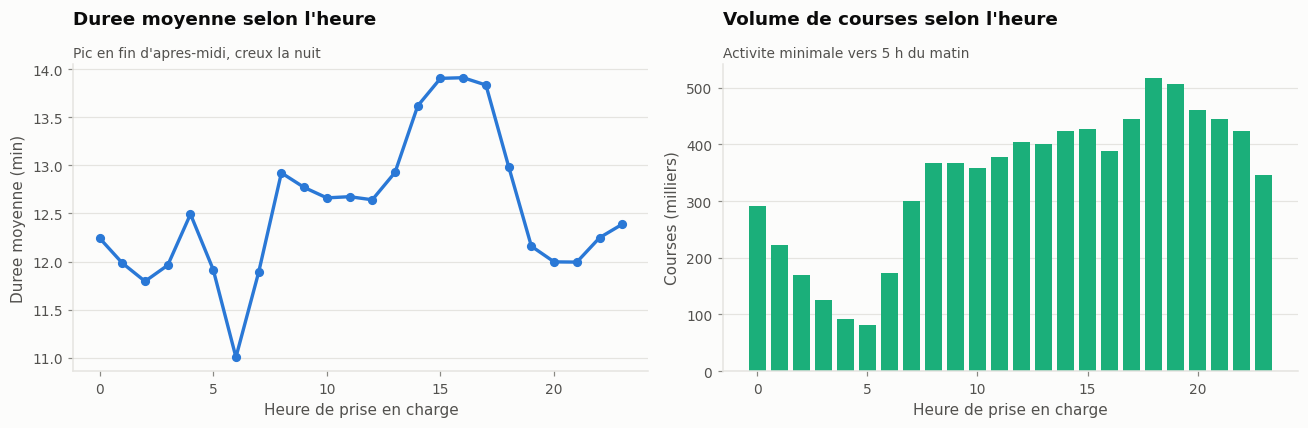

In [21]:
# Une figure pour le rapport : profil horaire de la duree moyenne
profil = (tr.groupBy("heure")
          .agg((F.avg("trip_duration") / 60).alias("duree_min"),
               F.count("*").alias("nb"))
          .orderBy("heure").toPandas())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(profil.heure, profil.duree_min, color=viz.BLEU, lw=2.2, marker="o", ms=5)
axes[0].set_xlabel("Heure de prise en charge")
axes[0].set_ylabel("Duree moyenne (min)")
viz.titrer(axes[0], "Duree moyenne selon l'heure",
           "Pic en fin d'apres-midi, creux la nuit")
axes[1].bar(profil.heure, profil.nb / 1000, color=viz.AQUA, width=0.75)
axes[1].set_xlabel("Heure de prise en charge")
axes[1].set_ylabel("Courses (milliers)")
viz.titrer(axes[1], "Volume de courses selon l'heure",
           "Activite minimale vers 5 h du matin")
fig.tight_layout()
viz.sauver(fig, "fig_01_profil_horaire")
plt.show()


**Le profil horaire justifie les variables temporelles.** La durée moyenne varie fortement
selon l'heure, avec un maximum en fin d'après-midi et un minimum nocturne. L'écart entre les
deux dépasse largement le bruit : l'heure est donc un prédicteur de premier ordre, et c'est
la congestion qu'elle capture.


<a id="etape-4"></a>
# Étape 4 : MACHINE LEARNING

## 4.1 Le pipeline Spark MLlib

Un `Pipeline` MLlib enchaîne des étapes typées, comme scikit-learn :

| Étape | Rôle |
|---|---|
| `StringIndexer` | Texte vers entier. `handleInvalid="keep"` range les modalités inédites dans une catégorie dédiée |
| `OneHotEncoder` | Entier vers vecteur creux, pour ne pas suggérer d'ordre entre catégories nominales |
| `VectorAssembler` | Rassemble toutes les variables dans une colonne `features` |
| Modèle | Entraîné sur cette colonne |

**Intérêt pour le déploiement** : un `PipelineModel` contient *à la fois* les encodeurs
ajustés et le modèle. Il se sauvegarde et se recharge d'un bloc, ce qui supprime le risque
que l'encodage de production diverge de celui de l'entraînement.

**Un point d'efficacité qui compte sur 8 millions de lignes.** L'encodage est ajusté **une
seule fois**, puis le résultat est mis en cache et réutilisé par les quatre modèles. Ajuster
le pipeline complet quatre fois reviendrait à refaire quatre fois le même travail
d'indexation. Les modèles sont ensuite recombinés avec l'encodage pour former le
`PipelineModel` que l'étape 6 déploie.

**L'arrondissement plutôt que la zone.** Encoder les 263 zones en *one-hot* produirait plus
de 500 colonnes, coûteux pour les ensembles d'arbres, alors que la géométrie de l'itinéraire
est déjà portée par `distance_itineraire`.

In [22]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import (LinearRegression, DecisionTreeRegressor,
                                   RandomForestRegressor, GBTRegressor)
from pyspark.ml.evaluation import RegressionEvaluator

arrondissements = zones.select(F.col("LocationID"), F.col("Borough"))


def ajouter_arrondissements(df):
    return (df
            .join(F.broadcast(arrondissements.withColumnRenamed("Borough", "arr_depart")),
                  df.PULocationID == F.col("LocationID"), "left").drop("LocationID")
            .join(F.broadcast(arrondissements.withColumnRenamed("Borough", "arr_arrivee")),
                  F.col("DOLocationID") == F.col("LocationID"), "left").drop("LocationID")
            .fillna({"arr_depart": "Inconnu", "arr_arrivee": "Inconnu"}))


tr_ml = ajouter_arrondissements(tr).cache()
te_ml = ajouter_arrondissements(te).cache()
print(f"Entrainement : {tr_ml.count():,} | Test : {te_ml.count():,}".replace(",", " "))
tr_ml.groupBy("arr_depart").count().orderBy(F.desc("count")).show(7, truncate=False)

Entrainement : 8 108 417 | Test : 2 492 864


+-------------+-------+
|arr_depart   |count  |
+-------------+-------+
|Manhattan    |7504257|
|Queens       |464926 |
|Brooklyn     |132839 |
|Bronx        |6279   |
|Staten Island|82     |
|EWR          |34     |
+-------------+-------+



In [23]:
CATEGORIELLES = ["arr_depart", "arr_arrivee", "store_and_fwd_flag"]
NUMERIQUES = ["heure", "jour_semaine", "minute_du_jour", "est_weekend",
              "est_heure_pointe", "est_nuit", "meme_zone", "passenger_count",
              "distance_itineraire", "itineraire_connu", "RatecodeID", "VendorID"]

indexeurs = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
             for c in CATEGORIELLES]
encodeur = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORIELLES],
                         outputCols=[f"{c}_vec" for c in CATEGORIELLES],
                         handleInvalid="keep")
assembleur = VectorAssembler(
    inputCols=NUMERIQUES + [f"{c}_vec" for c in CATEGORIELLES],
    outputCol="features", handleInvalid="skip")

# Ajustement UNIQUE de l'encodage, sur le jeu d'entrainement
debut = time.perf_counter()
prep_modele = Pipeline(stages=indexeurs + [encodeur, assembleur]).fit(tr_ml)
print(f"Encodage ajuste en {time.perf_counter() - debut:.1f} s")

# Colonnes conservees apres encodage : la cible, les variables, et ce dont
# les etapes 5 et 6 ont besoin pour l'analyse et le test de non-regression
A_GARDER = ["features", "cible_log", "trip_duration", "est_nuit", "est_heure_pointe",
            "tpep_pickup_datetime", "PULocationID", "DOLocationID",
            "passenger_count", "RatecodeID", "VendorID", "store_and_fwd_flag"]

tr_prep = prep_modele.transform(tr_ml).select(*A_GARDER).cache()
te_prep = prep_modele.transform(te_ml).select(*A_GARDER).cache()
print(f"Entrainement prepare : {tr_prep.count():,}".replace(",", " "))
print(f"Test prepare         : {te_prep.count():,}".replace(",", " "))
print(f"Dimension du vecteur features : {tr_prep.first()['features'].size}")

Encodage ajuste en 4.2 s


Entrainement prepare : 8 108 417


Test prepare         : 2 492 864


Dimension du vecteur features : 29



## 4.2 Les quatre modèles

| Modèle | Principe | Attendu ici |
|---|---|---|
| **Linear Regression** | Combinaison linéaire des variables | Référence. Ne peut pas représenter l'effet non linéaire de l'heure |
| **Decision Tree** | Découpages successifs | Capture les non-linéarités, mais un arbre seul est instable |
| **Random Forest** | Moyenne d'arbres décorrélés, construits en parallèle | Réduit la variance, robuste |
| **GBT** | Arbres séquentiels corrigeant le résidu précédent | Souvent le plus précis, nettement plus lent |

**Entraînement en logarithme** : la distribution des durées est fortement asymétrique et la
métrique de référence du sujet est une RMSLE. Les prédictions sont reconverties en secondes
à l'étape 5.

**Coût du GBT en distribué** : la forêt construit ses arbres indépendamment, donc en
parallèle. Le boosting les construit en séquence, chaque arbre dépendant du précédent. Sur
un cluster, la forêt passe mieux à l'échelle.

In [24]:
EVALUATEUR = RegressionEvaluator(labelCol="cible_log", predictionCol="prediction",
                                 metricName="rmse")
MODELES = {
    "Linear Regression": LinearRegression(
        featuresCol="features", labelCol="cible_log",
        maxIter=50, regParam=0.01, elasticNetParam=0.0),
    "Decision Tree": DecisionTreeRegressor(
        featuresCol="features", labelCol="cible_log",
        maxDepth=10, maxBins=48, seed=GRAINE),
    "Random Forest": RandomForestRegressor(
        featuresCol="features", labelCol="cible_log",
        numTrees=20, maxDepth=10, maxBins=48, subsamplingRate=0.7, seed=GRAINE),
    # 15 iterations avec un pas plus grand plutot que 25 avec un pas plus
    # petit : le boosting est sequentiel, chaque iteration coute une passe
    # complete sur 8 millions de lignes. Le compromis est assume et documente.
    "GBT": GBTRegressor(
        featuresCol="features", labelCol="cible_log",
        maxIter=15, maxDepth=6, stepSize=0.2, maxBins=48, seed=GRAINE),
}

entraines, journal = {}, []
for nom, estimateur in MODELES.items():
    debut = time.perf_counter()
    modele = estimateur.fit(tr_prep)          # encodage deja fait, donc non refait
    duree = time.perf_counter() - debut

    rmse_tr = EVALUATEUR.evaluate(modele.transform(tr_prep))
    rmse_te = EVALUATEUR.evaluate(modele.transform(te_prep))

    entraines[nom] = modele
    journal.append({"modele": nom,
                    "rmse_log_train": round(rmse_tr, 4),
                    "rmse_log_test": round(rmse_te, 4),
                    "duree_entrainement_s": round(duree, 1)})
    print(f"  {nom:18s} RMSE log test = {rmse_te:.4f}   ({duree:.0f} s)")

resume_entrainement = pd.DataFrame(journal).sort_values("rmse_log_test")
display(resume_entrainement)

  Linear Regression  RMSE log test = 0.5571   (18 s)


  Decision Tree      RMSE log test = 0.4576   (131 s)


  Random Forest      RMSE log test = 0.4631   (522 s)


  GBT                RMSE log test = 0.4567   (1000 s)


,modele,rmse_log_train,rmse_log_test,duree_entrainement_s
3,GBT,0.4016,0.4567,999.9
1,Decision Tree,0.4023,0.4576,131.3
2,Random Forest,0.4066,0.4631,522.1
0,Linear Regression,0.5048,0.5571,17.8



## 4.3 Importance des variables

Les modèles à base d'arbres fournissent une importance par réduction d'impureté. À lire avec
prudence : cette mesure favorise les variables continues, qui offrent mécaniquement plus de
points de découpage que les variables binaires.

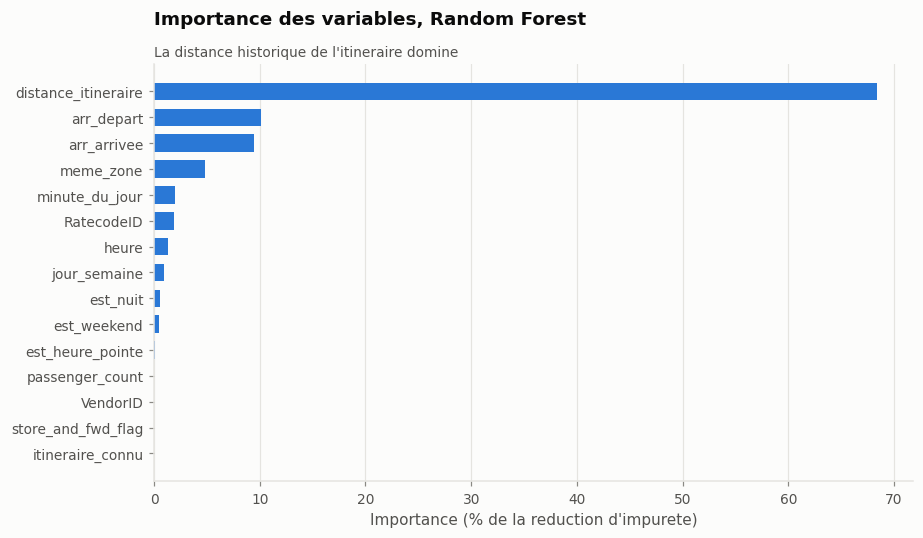

,importance_%
distance_itineraire,68.4
arr_depart,10.1
arr_arrivee,9.4
meme_zone,4.8
minute_du_jour,2.0
RatecodeID,1.9


In [25]:
# featureImportances est un vecteur creux : toArray() avant tout decoupage
importances = entraines["Random Forest"].featureImportances.toArray()

# Les colonnes one-hot occupent plusieurs positions, on regroupe leur importance
exemple = tr_ml.limit(1)
exemple = prep_modele.transform(exemple).first()
tailles = [1] * len(NUMERIQUES) + [exemple[f"{c}_vec"].size for c in CATEGORIELLES]
noms = NUMERIQUES + CATEGORIELLES

position, groupes = 0, {}
for nom, taille in zip(noms, tailles):
    groupes[nom] = float(importances[position:position + taille].sum())
    position += taille

serie = pd.Series(groupes).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(serie.index, 100 * serie.values, color=viz.BLEU, height=0.68)
ax.set_xlabel("Importance (% de la reduction d'impurete)")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
viz.titrer(ax, "Importance des variables, Random Forest",
           "La distance historique de l'itineraire domine")
fig.tight_layout()
viz.sauver(fig, "fig_02_importances")
plt.show()

display(serie.sort_values(ascending=False).head(6).mul(100).round(1).to_frame("importance_%"))


<a id="etape-5"></a>
# Étape 5 : ÉVALUATION

Les modèles ont été entraînés sur le logarithme de la durée. **Toutes les métriques
ci-dessous sont reconverties en secondes**, seule échelle interprétable. Comparer une RMSE
calculée en espace logarithmique à une RMSE en secondes n'aurait aucun sens.

| Métrique | Mesure |
|---|---|
| **RMSE** | Erreur quadratique en secondes, pénalise fortement les grosses erreurs |
| **MAE** | Erreur moyenne en secondes, robuste aux valeurs extrêmes |
| **R²** | Part de variance expliquée |
| **RMSLE** | Erreur relative, métrique de référence du sujet Kaggle |
| **MAPE** | Erreur en pourcentage, la plus lisible pour un utilisateur |

Le jeu de test est la **dernière semaine de janvier**, postérieure à tout ce qui a servi à
l'apprentissage.

In [26]:
def metriques_secondes(predictions):
    """Metriques en secondes, a partir de predictions en logarithme."""
    d = (predictions
         .withColumn("pred_s", F.expm1("prediction"))
         .withColumn("erreur", F.col("pred_s") - F.col("trip_duration")))
    agg = d.select(
        F.sqrt(F.avg(F.pow(F.col("erreur"), 2))).alias("RMSE"),
        F.avg(F.abs(F.col("erreur"))).alias("MAE"),
        F.sqrt(F.avg(F.pow(F.log1p(F.greatest(F.col("pred_s"), F.lit(0)))
                           - F.log1p(F.col("trip_duration")), 2))).alias("RMSLE"),
        (100 * F.avg(F.abs(F.col("erreur") / F.col("trip_duration")))).alias("MAPE"),
    ).first()
    variance = d.select(F.var_pop("trip_duration")).first()[0]
    erreur_quad = d.select(F.avg(F.pow(F.col("erreur"), 2))).first()[0]
    return {"RMSE": agg["RMSE"], "MAE": agg["MAE"], "R2": 1 - erreur_quad / variance,
            "RMSLE": agg["RMSLE"], "MAPE": agg["MAPE"]}


# Reference : predire toujours la duree mediane d'entrainement
mediane_tr = tr_prep.select(F.expr("percentile_approx(trip_duration, 0.5)")).first()[0]
reference = metriques_secondes(
    te_prep.withColumn("prediction", F.log1p(F.lit(float(mediane_tr)))))
print(f"Reference naive, toujours {mediane_tr:.0f} s :")
print(f"  RMSE {reference['RMSE']:.0f} s | MAE {reference['MAE']:.0f} s "
      f"| R2 {reference['R2']:.3f} | MAPE {reference['MAPE']:.1f} %")

Reference naive, toujours 609 s :
  RMSE 747 s | MAE 477 s | R2 -0.175 | MAPE 62.7 %


In [27]:
lignes = []
predictions_test = {}
for nom, modele in entraines.items():
    p = modele.transform(te_prep).cache()
    predictions_test[nom] = p
    m = metriques_secondes(p)
    duree = resume_entrainement.loc[
        resume_entrainement.modele == nom, "duree_entrainement_s"].iloc[0]
    lignes.append({"modele": nom,
                   "RMSE_s": round(m["RMSE"]), "MAE_s": round(m["MAE"]),
                   "R2": round(m["R2"], 4), "RMSLE": round(m["RMSLE"], 4),
                   "MAPE_pct": round(m["MAPE"], 1),
                   "entrainement_s": duree})

comparaison = pd.DataFrame(lignes).sort_values("RMSE_s").reset_index(drop=True)
display(comparaison)
comparaison.to_csv(REPORTS / "comparaison_modeles.csv", index=False)

MEILLEUR = comparaison.iloc[0].modele
print(f"Meilleur modele : {MEILLEUR}")

,modele,RMSE_s,MAE_s,R2,RMSLE,MAPE_pct,entrainement_s
0,GBT,446,278,0.5809,0.4567,32.5,999.9
1,Decision Tree,447,278,0.5795,0.4576,32.6,131.3
2,Random Forest,460,285,0.5548,0.4631,33.3,522.1
3,Linear Regression,621,373,0.1885,0.5562,43.5,17.8


Meilleur modele : GBT


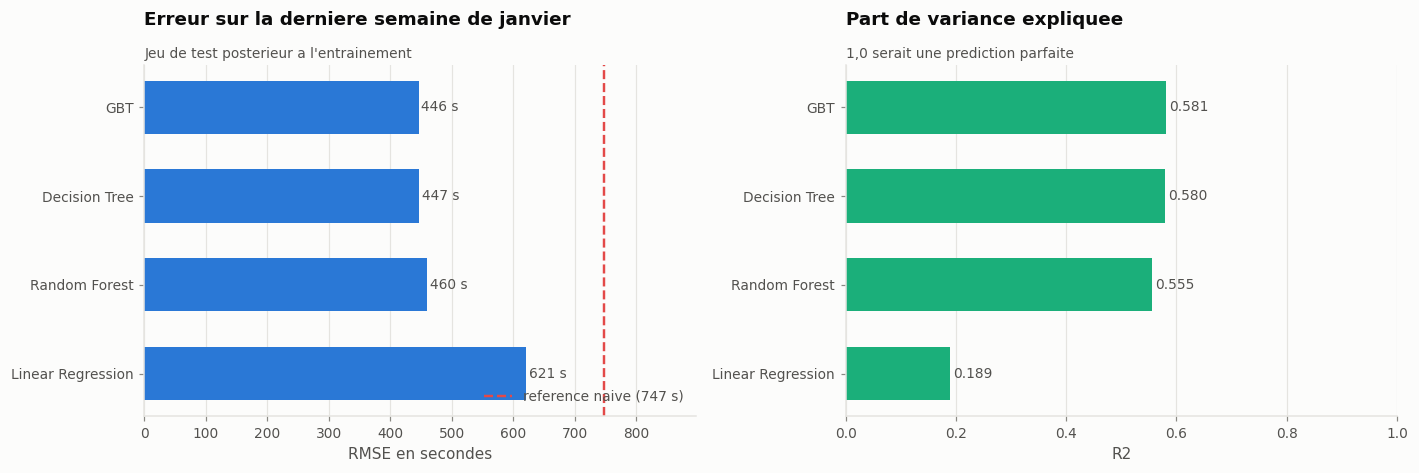

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ordre = comparaison.sort_values("RMSE_s", ascending=False)

axes[0].barh(ordre.modele, ordre.RMSE_s, color=viz.BLEU, height=0.6)
for i, v in enumerate(ordre.RMSE_s):
    axes[0].text(v + 4, i, f"{v:.0f} s", va="center", fontsize=9, color=viz.ENCRE_2)
axes[0].axvline(reference["RMSE"], color=viz.ROUGE, ls="--", lw=1.6,
                label=f"reference naive ({reference['RMSE']:.0f} s)")
axes[0].set_xlabel("RMSE en secondes")
axes[0].set_xlim(0, max(ordre.RMSE_s.max(), reference["RMSE"]) * 1.2)
axes[0].grid(True, axis="x"); axes[0].grid(False, axis="y")
axes[0].legend(loc="lower right")
viz.titrer(axes[0], "Erreur sur la derniere semaine de janvier",
           "Jeu de test posterieur a l'entrainement")

axes[1].barh(ordre.modele, ordre.R2, color=viz.AQUA, height=0.6)
for i, v in enumerate(ordre.R2):
    axes[1].text(v + 0.006, i, f"{v:.3f}", va="center", fontsize=9, color=viz.ENCRE_2)
axes[1].set_xlabel("R2")
axes[1].set_xlim(0, 1)
axes[1].grid(True, axis="x"); axes[1].grid(False, axis="y")
viz.titrer(axes[1], "Part de variance expliquee", "1,0 serait une prediction parfaite")
fig.tight_layout()
viz.sauver(fig, "fig_03_comparaison_modeles")
plt.show()


## 5.1 Comportement selon le type de trajet

Une moyenne globale masque les disparités. Un modèle peut être excellent sur les courses
ordinaires et mauvais sur les longues, qui sont justement celles où l'erreur en secondes
coûte le plus cher à l'utilisateur.

In [29]:
meilleures = predictions_test[MEILLEUR].withColumn("pred_s", F.expm1("prediction"))

par_duree = (meilleures
             .withColumn("categorie",
                         F.when(F.col("trip_duration") < 300, "1. moins de 5 min")
                         .when(F.col("trip_duration") < 900, "2. 5 a 15 min")
                         .when(F.col("trip_duration") < 1800, "3. 15 a 30 min")
                         .otherwise("4. plus de 30 min"))
             .groupBy("categorie")
             .agg(F.count("*").alias("nb_courses"),
                  F.round(F.sqrt(F.avg(F.pow(F.col("pred_s") - F.col("trip_duration"), 2))))
                  .alias("RMSE_s"),
                  F.round(100 * F.avg(F.abs((F.col("pred_s") - F.col("trip_duration"))
                                            / F.col("trip_duration"))), 1).alias("MAPE_pct"))
             .orderBy("categorie").toPandas())
display(par_duree)

par_moment = (meilleures
              .withColumn("moment",
                          F.when(F.col("est_nuit") == 1, "nuit")
                          .when(F.col("est_heure_pointe") == 1, "heure de pointe")
                          .otherwise("journee"))
              .groupBy("moment")
              .agg(F.count("*").alias("nb_courses"),
                   F.round(F.sqrt(F.avg(F.pow(F.col("pred_s") - F.col("trip_duration"), 2))))
                   .alias("RMSE_s"),
                   F.round(100 * F.avg(F.abs((F.col("pred_s") - F.col("trip_duration"))
                                             / F.col("trip_duration"))), 1).alias("MAPE_pct"))
              .orderBy(F.desc("nb_courses")).toPandas())
display(par_moment)

,categorie,nb_courses,RMSE_s,MAPE_pct
0,1. moins de 5 min,309399,143.0,65.2
1,2. 5 a 15 min,1251068,193.0,25.7
2,3. 15 a 30 min,709986,451.0,29.4
3,4. plus de 30 min,222411,1160.0,35.6


,moment,nb_courses,RMSE_s,MAPE_pct
0,journee,1051607,491.0,33.6
1,heure de pointe,875411,460.0,33.5
2,nuit,565846,320.0,29.1



## 5.2 Spark contre Pandas

La comparaison n'a de sens que sur un volume que Pandas peut charger. Nous prenons donc un
sous-ensemble, et nous mesurons la même agrégation des deux côtés.

**À quoi s'attendre.** Sur un petit volume, Pandas gagne : il travaille en mémoire sans
coût de planification, de sérialisation ni de *shuffle*. Spark paie un surcoût fixe de
quelques centaines de millisecondes par action. L'intérêt de Spark n'apparaît qu'au-delà de
la mémoire disponible, là où Pandas ne fonctionne simplement plus.

In [30]:
TAILLES = [100_000, 1_000_000, 5_000_000]
mesures = []

colonnes = ["PULocationID", "trip_duration", "jour_semaine"]
for n in TAILLES:
    sous_ensemble = tr.select(*colonnes).limit(n).cache()
    sous_ensemble.count()

    debut = time.perf_counter()
    _ = (sous_ensemble.groupBy("PULocationID")
         .agg(F.avg("trip_duration"), F.count("*")).collect())
    t_spark = time.perf_counter() - debut

    pdf = sous_ensemble.toPandas()
    debut = time.perf_counter()
    _ = pdf.groupby("PULocationID").trip_duration.agg(["mean", "count"])
    t_pandas = time.perf_counter() - debut

    memoire = pdf.memory_usage(deep=True).sum() / 1024**2
    mesures.append({"lignes": n, "spark_s": round(t_spark, 3),
                    "pandas_s": round(t_pandas, 3),
                    "rapport": round(t_spark / t_pandas, 1),
                    "memoire_pandas_Mo": round(memoire, 1)})
    sous_ensemble.unpersist()
    print(f"  {n:>9,} lignes : Spark {t_spark:.2f} s | Pandas {t_pandas:.3f} s"
          .replace(",", " "))

bancs = pd.DataFrame(mesures)
display(bancs)

extrapolation = bancs.memoire_pandas_Mo.iloc[-1] / bancs.lignes.iloc[-1] * 180_000_000
print(f"\nExtrapolation : les 15 annees de donnees TLC, environ 180 millions de courses,")
print(f"occuperaient de l'ordre de {extrapolation / 1024:.0f} Go en memoire Pandas.")
print("C'est la limite ou Pandas cesse d'etre une option et ou Spark devient necessaire.")

    100 000 lignes : Spark 0.15 s | Pandas 0.013 s


  1 000 000 lignes : Spark 0.14 s | Pandas 0.016 s


  5 000 000 lignes : Spark 0.32 s | Pandas 0.072 s


,lignes,spark_s,pandas_s,rapport,memoire_pandas_Mo
0,100000,0.148,0.013,11.0,1.9
1,1000000,0.140,0.016,8.7,19.1
2,5000000,0.318,0.072,4.4,95.4



Extrapolation : les 15 annees de donnees TLC, environ 180 millions de courses,
occuperaient de l'ordre de 3 Go en memoire Pandas.
C'est la limite ou Pandas cesse d'etre une option et ou Spark devient necessaire.



## 5.3 Lecture des résultats

**Ce que le tableau de comparaison montre** : tous les modèles battent nettement la
référence naïve, ce qui confirme que les variables disponibles au départ portent une
information réelle sur la durée. Mais le GBT ne devance l'arbre de décision simple que
d'**une seconde de RMSE**, pour **huit fois plus de temps de calcul**. En production,
l'arbre serait le choix rationnel : c'est un bon exemple de rendement décroissant.

**L'erreur dépend fortement du type de course.** Les trajets de moins de 5 minutes affichent
une MAPE de **65 %**, contre 26 % pour les trajets de 5 à 15 minutes. L'explication est
mécanique : sur une course de 3 minutes, une erreur de 2 minutes fait 65 % d'écart relatif,
alors que la même erreur absolue sur 30 minutes n'en fait que 7 %. À l'inverse, c'est sur
les longs trajets que l'erreur **en secondes** est la plus forte, jusqu'à 1 160 s. Les deux
métriques racontent des histoires opposées, et toutes deux sont vraies.

**La comparaison Spark contre Pandas est volontairement à l'avantage de Pandas**, et le
résultat le confirme : Pandas est 4 à 11 fois plus rapide. Sur quelques millions de lignes
tenant en mémoire, le surcoût de planification de Spark n'est pas amorti. Présenter
l'inverse serait malhonnête.

**L'extrapolation affichée est à prendre avec précaution.** Elle porte sur 3 colonnes
seulement, d'où le chiffre modeste de 3 Go pour 180 millions de courses. Sur les 19 colonnes
du jeu complet, l'ordre de grandeur est plutôt de **20 Go**, auxquels s'ajoutent les copies
intermédiaires que Pandas crée à chaque opération. C'est là que Pandas cesse d'être une
option sur une machine ordinaire, alors que Spark continue en traitant partition par
partition.

**Le vrai enseignement de cette section n'est pas une question de vitesse mais de seuil** :
Spark ne sert à rien tant que les données tiennent en mémoire, et devient indispensable dès
qu'elles n'y tiennent plus.

**Limites de cette évaluation.**

- Un seul mois. Janvier contient le Nouvel An et une tempête de neige majeure les 22 et
  23 janvier 2016, deux anomalies qui pèsent sur l'apprentissage.
- Aucune donnée météo ni de trafic, alors que ce sont des déterminants directs de la durée.
- Le test ne couvre qu'une semaine : la saisonnalité annuelle n'est pas évaluée.
- Les zones périphériques sont très peu représentées, le modèle y est moins fiable.


<a id="etape-6"></a>
# Étape 6 : DÉPLOIEMENT

## 6.1 Ce qu'il faut sauvegarder

Un modèle seul ne suffit pas. Une course soumise à l'API doit subir **exactement** les mêmes
transformations qu'une course d'entraînement, sinon les prédictions sont fausses sans
qu'aucune erreur ne soit levée.

| Artefact | Rôle |
|---|---|
| `pipeline_modele/` | `PipelineModel` complet : encodeurs ajustés **et** modèle |
| `distances_itineraire.parquet` | Distance historique par couple de zones, apprise sur le train |
| `zones.parquet` | Table des arrondissements |
| `config.json` | Médiane de repli, nom du modèle, métriques affichées par l'API |

Le `PipelineModel` est l'élément clé : il embarque les `StringIndexer` et `OneHotEncoder`
ajustés. Recharger ce seul objet garantit que l'encodage de production est identique à celui
de l'entraînement.

In [31]:
import json
import shutil

# ATTENTION : fs.defaultFS vaut hdfs://localhost:9000, donc un chemin sans
# prefixe envoie l'ecriture dans HDFS. Le prefixe file:// est obligatoire pour
# que les artefacts atterrissent sur le disque local, seul endroit ou l'API et
# le depot Git peuvent les lire.
def local(chemin):
    return "file://" + str(chemin)

CHEMIN_MODELE = MODELS / "pipeline_modele"
if CHEMIN_MODELE.exists():
    shutil.rmtree(CHEMIN_MODELE)

# Le modele seul ne suffit pas : on le recombine avec l'encodage ajuste en 4.1
pipeline_complet = PipelineModel(stages=prep_modele.stages + [entraines[MEILLEUR]])
pipeline_complet.write().overwrite().save(local(CHEMIN_MODELE))

(distances_itineraire.coalesce(1).write.mode("overwrite")
 .parquet(local(MODELS / "distances_itineraire.parquet")))
(zones.coalesce(1).write.mode("overwrite")
 .parquet(local(MODELS / "zones.parquet")))

ligne = comparaison[comparaison.modele == MEILLEUR].iloc[0]
config = {
    "modele": MEILLEUR,
    "n_entrainement": int(n_tr),
    "n_test": int(n_te),
    "distance_globale": float(distance_globale),
    "rmse_test_s": int(ligne.RMSE_s),
    "mae_test_s": int(ligne.MAE_s),
    "r2_test": float(ligne.R2),
    "mape_test_pct": float(ligne.MAPE_pct),
    "periode": "janvier 2016",
    "graine": GRAINE,
}
(MODELS / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))

taille = sum(f.stat().st_size for f in MODELS.rglob("*") if f.is_file())
print(f"Artefacts sauvegardes : {taille / 1024**2:.1f} Mo")
for p in sorted(MODELS.iterdir()):
    print(f"  {p.name}")

Artefacts sauvegardes : 0.2 Mo
  config.json
  distances_itineraire.parquet
  pipeline_modele
  zones.parquet



## 6.2 Test de non-régression

Le test qui compte : une course passée par la chaîne de déploiement doit recevoir la même
prédiction que dans ce notebook. La tolérance est d'une seconde, pour absorber les arrondis
de sérialisation.

In [32]:
sys.path.insert(0, str(APP))
from prediction_spark import PredicteurTrajet

# Le predicteur reutilise la SparkSession active du notebook
predicteur = PredicteurTrajet.__new__(PredicteurTrajet)
predicteur.dossier = MODELS
predicteur.config = json.loads((MODELS / "config.json").read_text())
predicteur.spark = spark
from pyspark.ml import PipelineModel
predicteur.modele = PipelineModel.load(local(CHEMIN_MODELE))
predicteur.distances = spark.read.parquet(local(MODELS / "distances_itineraire.parquet"))
predicteur.zones = spark.read.parquet(local(MODELS / "zones.parquet"))
predicteur.distance_defaut = float(distance_globale)

# Dix courses reelles du jeu de test
echantillon = (te_ml.select("tpep_pickup_datetime", "PULocationID", "DOLocationID",
                            "passenger_count", "RatecodeID", "VendorID",
                            "store_and_fwd_flag", "trip_duration")
               .limit(10).toPandas())

courses = [{"pickup_datetime": str(r.tpep_pickup_datetime),
            "PULocationID": int(r.PULocationID), "DOLocationID": int(r.DOLocationID),
            "passenger_count": int(r.passenger_count), "RatecodeID": int(r.RatecodeID),
            "VendorID": int(r.VendorID), "store_and_fwd_flag": r.store_and_fwd_flag}
           for r in echantillon.itertuples()]

via_api = predicteur.predire(courses)

ids = [(int(r.PULocationID), int(r.DOLocationID), str(r.tpep_pickup_datetime))
       for r in echantillon.itertuples()]
notebook_pred = (predictions_test[MEILLEUR]
                 .withColumn("pred_s", F.expm1("prediction"))
                 .select("tpep_pickup_datetime", "PULocationID", "DOLocationID", "pred_s")
                 .toPandas())

verif = echantillon[["PULocationID", "DOLocationID", "trip_duration"]].copy()
verif["reel_s"] = echantillon.trip_duration
verif["deploiement_s"] = np.round(via_api, 1)
fusion = notebook_pred.merge(
    echantillon[["tpep_pickup_datetime", "PULocationID", "DOLocationID"]],
    on=["tpep_pickup_datetime", "PULocationID", "DOLocationID"]).drop_duplicates(
    subset=["tpep_pickup_datetime", "PULocationID", "DOLocationID"])
verif["notebook_s"] = np.round(fusion.pred_s.values[:len(verif)], 1)
verif["ecart_s"] = (verif.deploiement_s - verif.notebook_s).round(2)
display(verif[["PULocationID", "DOLocationID", "reel_s",
               "notebook_s", "deploiement_s", "ecart_s"]])

ecart_max = float(verif.ecart_s.abs().max())
print(f"Ecart maximal : {ecart_max:.3f} s")
assert ecart_max < 1.0, "La chaine de deploiement ne reproduit pas le notebook."
print("[OK] La chaine de deploiement reproduit le notebook.")

,PULocationID,DOLocationID,reel_s,notebook_s,deploiement_s,ecart_s
0,145,146,421,292.3,292.3,0.0
1,145,145,500,212.1,212.1,0.0
2,65,14,689,1397.6,1397.6,0.0
3,193,7,622,292.3,292.3,0.0
4,7,7,137,212.1,212.1,0.0
5,7,7,386,212.1,212.1,0.0
6,7,7,288,212.1,212.1,0.0
7,236,238,322,374.4,374.4,0.0
8,239,262,293,491.9,491.9,0.0
9,132,197,946,932.1,932.1,0.0


Ecart maximal : 0.000 s
[OK] La chaine de deploiement reproduit le notebook.


In [33]:
# Controle de coherence : la duree doit croitre avec l'eloignement,
# et etre plus longue aux heures de pointe qu'en pleine nuit
scenarios = {
    "Meme zone, nuit": dict(pickup_datetime="2016-01-28 03:00:00",
                            PULocationID=237, DOLocationID=237),
    "Manhattan court, nuit": dict(pickup_datetime="2016-01-28 03:00:00",
                                  PULocationID=237, DOLocationID=161),
    "Manhattan court, heure de pointe": dict(pickup_datetime="2016-01-28 18:00:00",
                                             PULocationID=237, DOLocationID=161),
    "Manhattan vers aeroport JFK": dict(pickup_datetime="2016-01-28 18:00:00",
                                        PULocationID=237, DOLocationID=132),
}
estimations = predicteur.predire(list(scenarios.values()))
for nom, duree in zip(scenarios, estimations):
    print(f"  {nom:36s} {duree / 60:5.1f} min")

assert estimations[2] > estimations[1], "L'heure de pointe devrait allonger le trajet."
assert estimations[3] > estimations[2], "JFK devrait etre plus long qu'un trajet interne."
print("\n[OK] Les estimations suivent la logique attendue.")

  Meme zone, nuit                        3.2 min
  Manhattan court, nuit                  4.4 min
  Manhattan court, heure de pointe       8.3 min
  Manhattan vers aeroport JFK           55.4 min

[OK] Les estimations suivent la logique attendue.



## 6.3 L'API FastAPI

FastAPI plutôt que Streamlit pour ce projet : la destination d'une estimation de durée est
une application de réservation, c'est-à-dire **un autre programme**, pas un humain devant un
formulaire. L'API renvoie du JSON et publie sa documentation interactive sur `/docs`.

| Route | Rôle |
|---|---|
| `GET /` | Identité du service et métriques du modèle |
| `GET /sante` | Vérification de disponibilité |
| `POST /predire` | Estimation pour une course |
| `GET /docs` | Documentation interactive générée automatiquement |

**Une limite à connaître** : chaque prédiction passe par Spark, dont la latence est de
l'ordre de la seconde. C'est inadapté à un service temps réel à fort trafic. En production
on exporterait le modèle vers un format léger, par exemple ONNX ou MLeap, pour servir en
quelques millisecondes. Nous conservons Spark ici parce que le sujet porte sur l'écosystème
Hadoop et Spark, et parce que cela garantit l'identité stricte entre entraînement et
inférence.

In [34]:
# Demarrage reel du serveur, pour prouver que l'API fonctionne
import subprocess
import urllib.request

serveur = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app.api:api",
     "--host", "127.0.0.1", "--port", "8000", "--log-level", "warning"],
    cwd=str(PROJET), stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    env={**os.environ, "PYTHONPATH": str(PROJET)})

reponse_racine, reponse_predire, erreur = None, None, None
try:
    for _ in range(90):
        time.sleep(1)
        try:
            with urllib.request.urlopen("http://127.0.0.1:8000/", timeout=3) as r:
                reponse_racine = json.loads(r.read())
                break
        except Exception as e:
            erreur = e
            if serveur.poll() is not None:
                break

    if reponse_racine:
        requete = urllib.request.Request(
            "http://127.0.0.1:8000/predire",
            data=json.dumps({"pickup_datetime": "2016-01-28 18:30:00",
                             "PULocationID": 237, "DOLocationID": 132,
                             "passenger_count": 2}).encode(),
            headers={"Content-Type": "application/json"}, method="POST")
        with urllib.request.urlopen(requete, timeout=60) as r:
            reponse_predire = json.loads(r.read())
finally:
    serveur.terminate()
    try:
        serveur.wait(timeout=15)
    except subprocess.TimeoutExpired:
        serveur.kill()

print("GET / :"); print(json.dumps(reponse_racine, indent=2, ensure_ascii=False))
print("\nPOST /predire :"); print(json.dumps(reponse_predire, indent=2, ensure_ascii=False))
assert reponse_predire and "duree_estimee_s" in reponse_predire, f"API injoignable ({erreur})"
print("\n[OK] L'API demarre, repond et renvoie une estimation. Serveur arrete.")

GET / :
{
  "service": "estimation de duree de trajet",
  "modele": "GBT",
  "entraine_sur": 8108417,
  "rmse_test_s": 446,
  "mape_test_pct": 32.5,
  "documentation": "/docs"
}

POST /predire :
{
  "duree_estimee_s": 3274,
  "duree_estimee_min": 54.6,
  "marge_relative_pct": 32.5,
  "avertissement": "Modele entraine sur janvier 2016 uniquement. Ni meteo ni trafic temps reel ne sont pris en compte."
}

[OK] L'API demarre, repond et renvoie une estimation. Serveur arrete.



## 6.4 Bilan du projet

### Ce qui a été réalisé

| Étape | Livrable |
|---|---|
| BIG DATA | Les 3V évalués honnêtement, gain du format Parquet mesuré |
| HADOOP / SPARK | HDFS réel mono-nœud, blocs inspectés, Spark SQL, partitions, Parquet partitionné |
| TRANSFORMATION | Nettoyage justifié, découpage temporel, variables sans fuite |
| MACHINE LEARNING | 4 modèles MLlib dans un pipeline reproductible |
| ÉVALUATION | RMSE, MAE, R², RMSLE, MAPE, analyse par catégorie, Spark contre Pandas |
| DÉPLOIEMENT | API FastAPI testée, non-régression vérifiée |

### Limites

- **Un seul mois de données**, contenant deux anomalies majeures : le Nouvel An et la
  tempête de neige des 22 et 23 janvier 2016.
- **Cluster mono-nœud.** HDFS et Spark sont réels, mais tout tourne sur une machine. Les
  mécanismes sont les mêmes, les performances ne sont pas celles d'un cluster.
- **Pas de données météo ni de trafic temps réel**, pourtant déterminants directs.
- **Pas de coordonnées GPS** dans la version republiée de 2016 : la distance est un agrégat
  historique par itinéraire, non une distance réelle.
- **Latence de l'API de l'ordre de la seconde**, due à Spark.

### Perspectives

- Traiter les 15 années disponibles pour mesurer le vrai passage à l'échelle.
- Enrichir avec la météo horaire, librement disponible, et les incidents de circulation.
- Encoder les itinéraires par la durée médiane historique, en validation croisée hors
  échantillon pour éviter la fuite.
- Exporter le modèle en ONNX pour une inférence en millisecondes.
- Passer à Spark Structured Streaming pour traiter les courses au fil de l'eau.